In [2]:
#### Install scvi-tools
!pip install --quiet scvi-colab
from scvi_colab import install
run_outside_colab=True
install()

In [33]:
!pip3 install igraph
!pip install leidenalg

  Using cached igraph-1.0.0-cp39-abi3-macosx_11_0_arm64.whl.metadata (4.4 kB)
Using cached igraph-1.0.0-cp39-abi3-macosx_11_0_arm64.whl (2.0 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [igraph]


In [34]:
import igraph

In [7]:
### import the required packages
import os
import tempfile

import scanpy as sc
import scvi
import seaborn as sns
import torch
import anndata

In [4]:
scvi.settings.seed = 0
print("Last run with scvi-tools version:", scvi.__version__)

Seed set to 0


Last run with scvi-tools version: 1.5.0.post1


In [5]:
sc.set_figure_params(figsize=(6, 6), frameon=False)
sns.set_theme()
torch.set_float32_matmul_precision("high")
save_dir = tempfile.TemporaryDirectory()

%config InlineBackend.print_figure_kwargs={"facecolor": "w"}
%config InlineBackend.figure_format="retina"

In [8]:

### load the h5ad  of the merged un integrated impac data
adata = anndata.read_h5ad('/Users/brendakarumbo/Desktop/PhD/Project/IM_samples/processed_samples_with_labels/unintegrated_IMPAC.h5ad')

In [9]:
adata

AnnData object with n_obs × n_vars = 61198 × 25562
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Tissue', 'Condition', 'Study', 'percent.mt', 'RNA_snn_res.0.5', 'seurat_clusters', 'predicted.id', 'prediction.score.CD16.Mono', 'prediction.score.pDC', 'prediction.score.Plasma.cell', 'prediction.score.NK', 'prediction.score.B.cell', 'prediction.score.HSPC', 'prediction.score.CD4.Tcell', 'prediction.score.Neutrophil', 'prediction.score.gdT', 'prediction.score.DC', 'prediction.score.CD8.Tcell', 'prediction.score.CD14.Mono', 'prediction.score.Platelet', 'prediction.score.MAIT', 'prediction.score.Treg', 'prediction.score.ILC', 'prediction.score.dnT', 'prediction.score.Eryth', 'prediction.score.max', 'pANN_0.25_0.09_171', 'DF.classifications_0.25_0.09_171', 'DF.classifications_0.25_0.09_152', 'doublet_classification', 'pANN_0.25_0.09_130', 'DF.classifications_0.25_0.09_130', 'DF.classifications_0.25_0.09_115', 'pANN_0.25_0.09_39', 'DF.classifications_0.25_0.09_39', 'DF.classifications_

In [10]:
#### preprocess the dataset removing cells with few genes
sc.pp.filter_genes(adata, min_counts=3)

In [11]:
adata.layers["counts"] = adata.X.copy()  # preserve counts
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata) # normalize the data
adata.raw = adata  # freeze the state in `.raw`

In [12]:
### select the variable genes
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=1200,
    subset=True,
    layer="counts",
    flavor="seurat_v3",
    batch_key="orig.ident",
)

In [13]:
### set up the anndata
scvi.model.SCVI.setup_anndata(
    adata,
    layer="counts",
    batch_key= "orig.ident",
    continuous_covariate_keys=["percent.mt"],
)

In [14]:
### create the model 
model = scvi.model.SCVI(adata)

In [15]:
#### We can see an overview of the model by printing it.
model


SCVI model with the following parameters: 
n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb, 
latent_distribution: normal.
Training status: Not Trained
Model's adata is minified?: False

In [16]:
### train the model
model.train(train_size=0.8, check_val_every_n_epoch=1)

/Users/brendakarumbo/anaconda3/lib/python3.13/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been automatically set to `cpu` although 'mps' exists. If you wish to run on mps backend, use explicitly accelerator='mps' in train function.In future releases it will become default for mps supported machines.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
/Users/brendakarumbo/anaconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/brendakarumbo/anaconda3/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstanc

Training:   0%|          | 0/131 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=131` reached.


In [17]:
#### Do the savedir 

import os

save_dir = "/Users/brendakarumbo/Desktop/PhD/Project/IM_samples/processed_samples_with_labels/scvi_results"

os.makedirs(save_dir, exist_ok=True)

In [19]:
### save the model and the weights
#Saving consists of saving the model neural network weights, as well as parameters used to initialize the model.

model_dir = os.path.join(save_dir, "scvi_model")
model.save(model_dir, overwrite=True)

In [20]:
model_dir

'/Users/brendakarumbo/Desktop/PhD/Project/IM_samples/processed_samples_with_labels/scvi_results/scvi_model'

In [21]:
model = scvi.model.SCVI.load(model_dir, adata=adata)

INFO     File                                                                                                      
         /Users/brendakarumbo/Desktop/PhD/Project/IM_samples/processed_samples_with_labels/scvi_results/scvi_model/
         model.pt already downloaded                                                                               


/Users/brendakarumbo/anaconda3/lib/python3.13/site-packages/scvi/model/base/_base_model.py:961: UserWarning: `accelerator` has been automatically set to `cpu` although 'mps' exists. If you wish to run on mps backend, use explicitly accelerator='mps' in train function.In future releases it will become default for mps supported machines.
  _, _, device = parse_device_args(


In [22]:
#### plot the loss curves
import matplotlib.pyplot as plt

hist = model.history


def plot_metric(train_key, val_key, title, ylabel):
    plt.figure(figsize=(6, 4))
    plt.plot(hist[train_key], label="train")
    plt.plot(hist[val_key], label="validation")
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

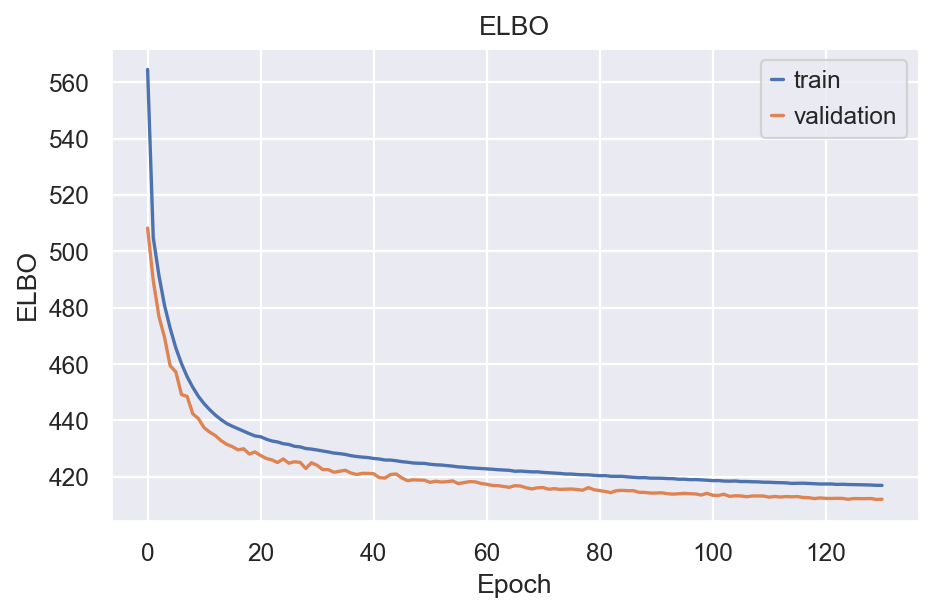

In [23]:
# Negative ELBO (Evidence lower bound)
if "elbo_train" in hist:
    plot_metric("elbo_train", "elbo_validation", "ELBO", "ELBO")

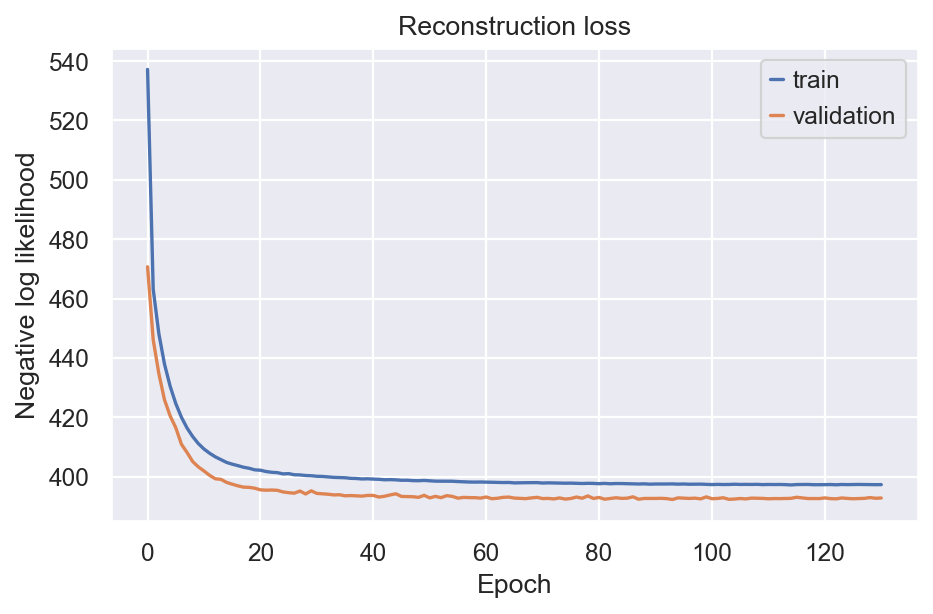

In [24]:
# Reconstruction loss
plot_metric(
    "reconstruction_loss_train",
    "reconstruction_loss_validation",
    "Reconstruction loss",
    "Negative log likelihood",
)

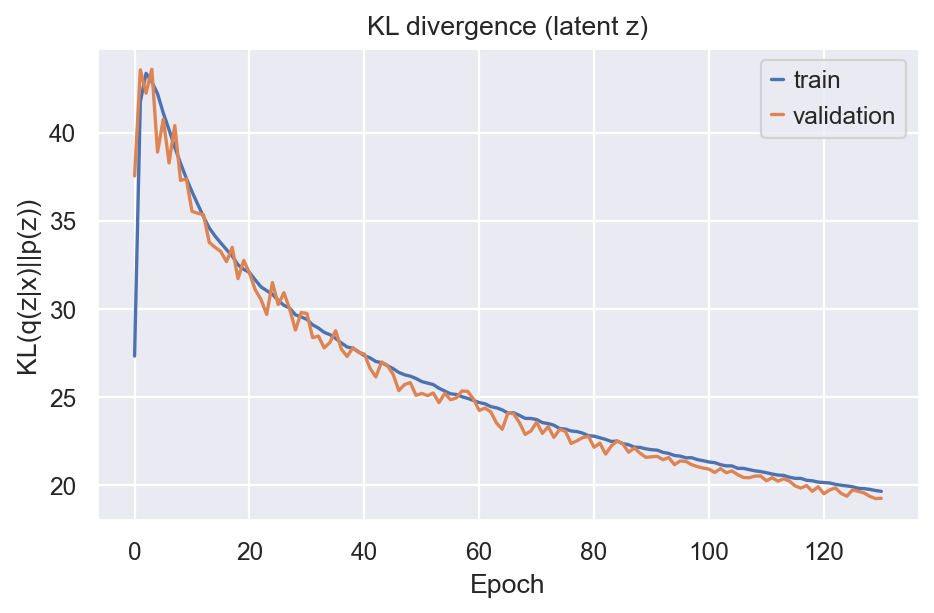

In [25]:
# Local KL divergence
plot_metric(
    "kl_local_train", "kl_local_validation", "KL divergence (latent z)", "KL(q(z|x)||p(z))"
)

In [26]:
###It’s often useful to store the outputs of scvi-tools back into the original anndata, as it permits interoperability with Scanpy.

SCVI_LATENT_KEY = "X_scVI"

latent = model.get_latent_representation()
adata.obsm[SCVI_LATENT_KEY] = latent
latent.shape

(61198, 10)

In [27]:
### Let’s store the normalized values back in the anndata.
SCVI_NORMALIZED_KEY = "scvi_normalized"

adata.layers[SCVI_NORMALIZED_KEY] = model.get_normalized_expression(library_size=10e4)

In [28]:
##visualize without integration 
# run PCA then generate UMAP plots
sc.tl.pca(adata)
sc.pp.neighbors(adata, n_pcs=30, n_neighbors=20)
sc.tl.umap(adata, min_dist=0.3)

/Users/brendakarumbo/anaconda3/lib/python3.13/site-packages/sklearn/utils/sparsefuncs.py:734: RuntimeWarning: divide by zero encountered in matmul
  matvec=lambda x: X @ x - offset @ x,
/Users/brendakarumbo/anaconda3/lib/python3.13/site-packages/sklearn/utils/sparsefuncs.py:734: RuntimeWarning: overflow encountered in matmul
  matvec=lambda x: X @ x - offset @ x,
/Users/brendakarumbo/anaconda3/lib/python3.13/site-packages/sklearn/utils/sparsefuncs.py:734: RuntimeWarning: invalid value encountered in matmul
  matvec=lambda x: X @ x - offset @ x,
/Users/brendakarumbo/anaconda3/lib/python3.13/site-packages/sklearn/utils/sparsefuncs.py:735: RuntimeWarning: divide by zero encountered in matmul
  matmat=lambda x: X @ x - offset @ x,
/Users/brendakarumbo/anaconda3/lib/python3.13/site-packages/sklearn/utils/sparsefuncs.py:735: RuntimeWarning: overflow encountered in matmul
  matmat=lambda x: X @ x - offset @ x,
/Users/brendakarumbo/anaconda3/lib/python3.13/site-packages/sklearn/utils/sparsefun

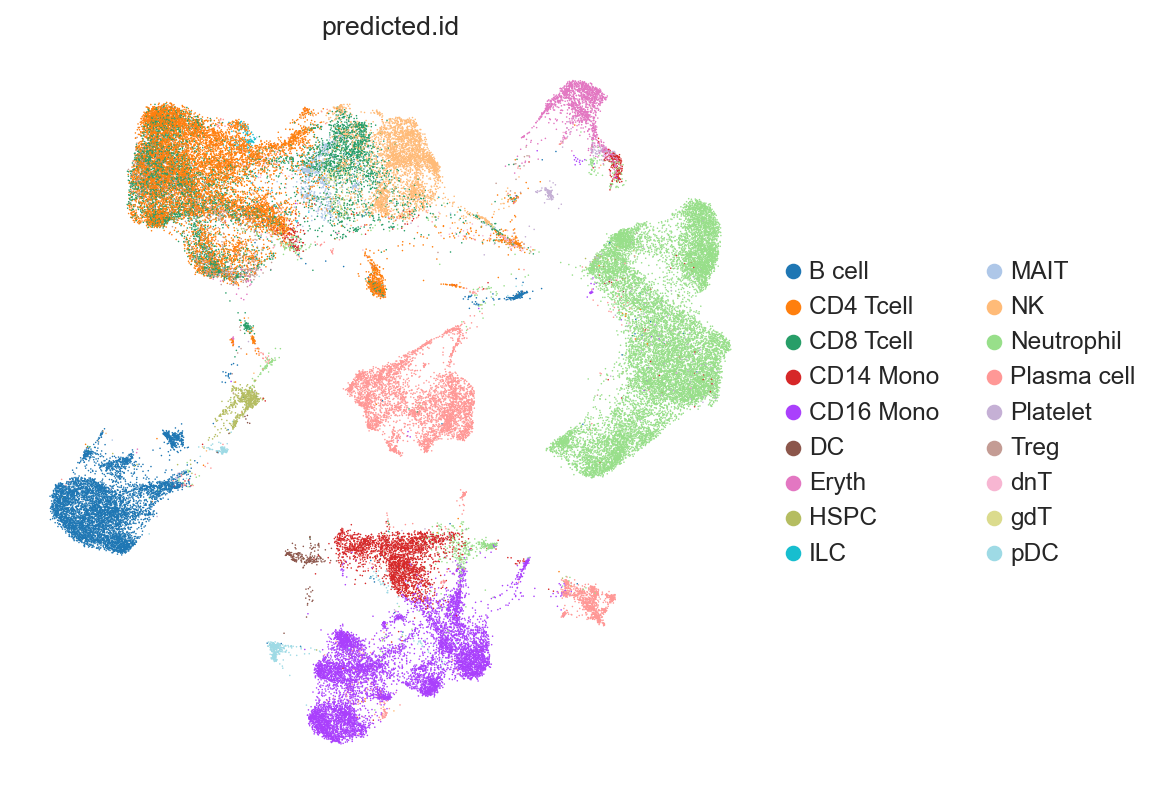

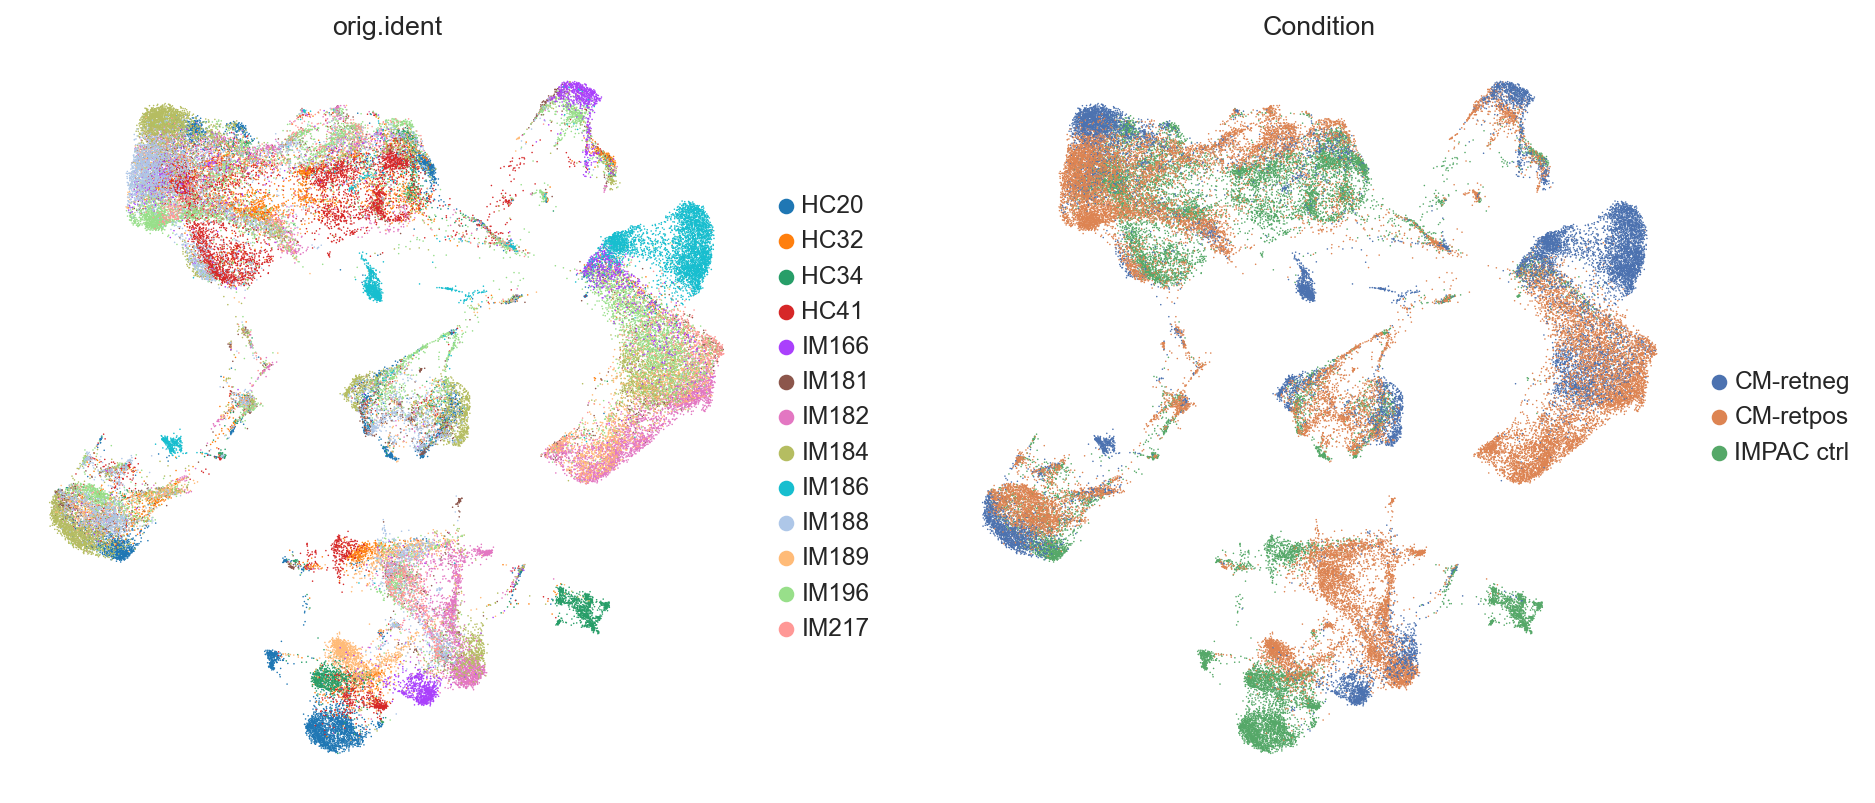

In [29]:
sc.pl.umap(
    adata,
    color=["predicted.id"],
    frameon=False,
)
sc.pl.umap(
    adata,
    color=["orig.ident", "Condition"],
    ncols=2,
    frameon=False,
)

In [30]:
###Now, let us try using the scVI latent space to generate the same UMAP plots to see if scVI successfully accounts for batch effects in the data.

# use scVI latent space for UMAP generation
sc.pp.neighbors(adata, use_rep=SCVI_LATENT_KEY)
sc.tl.umap(adata, min_dist=0.3)


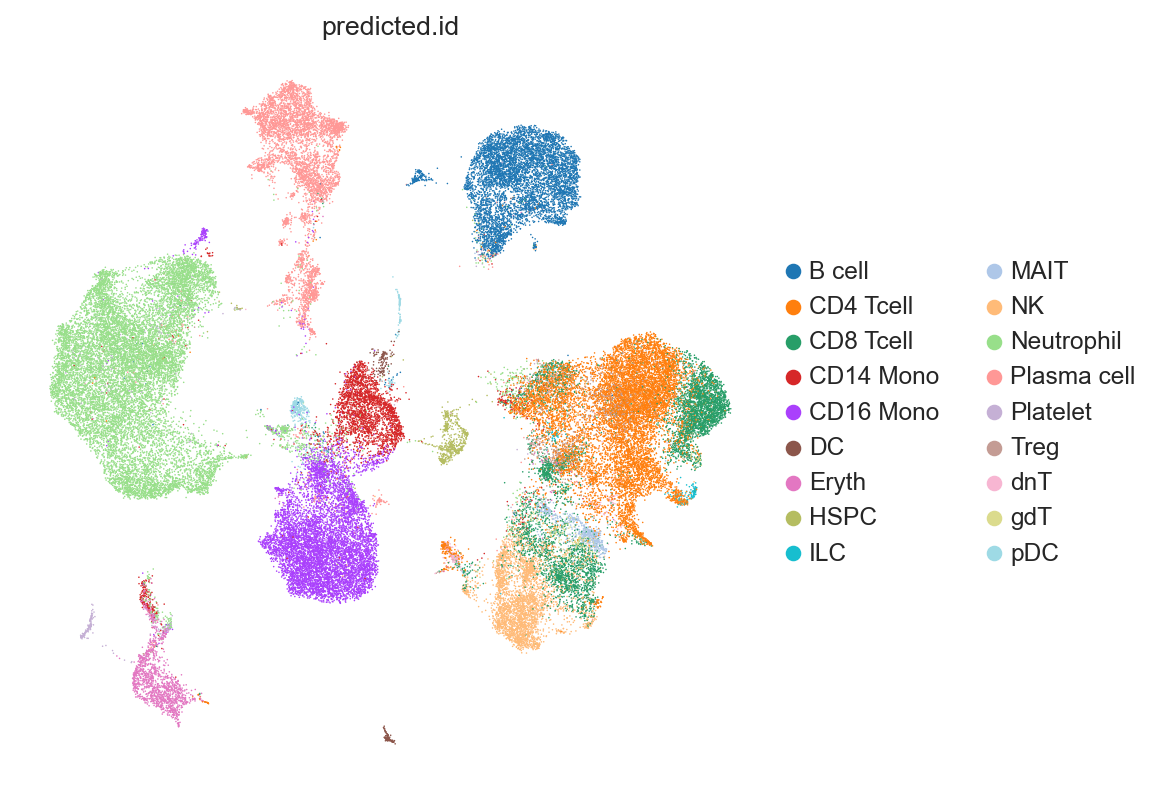

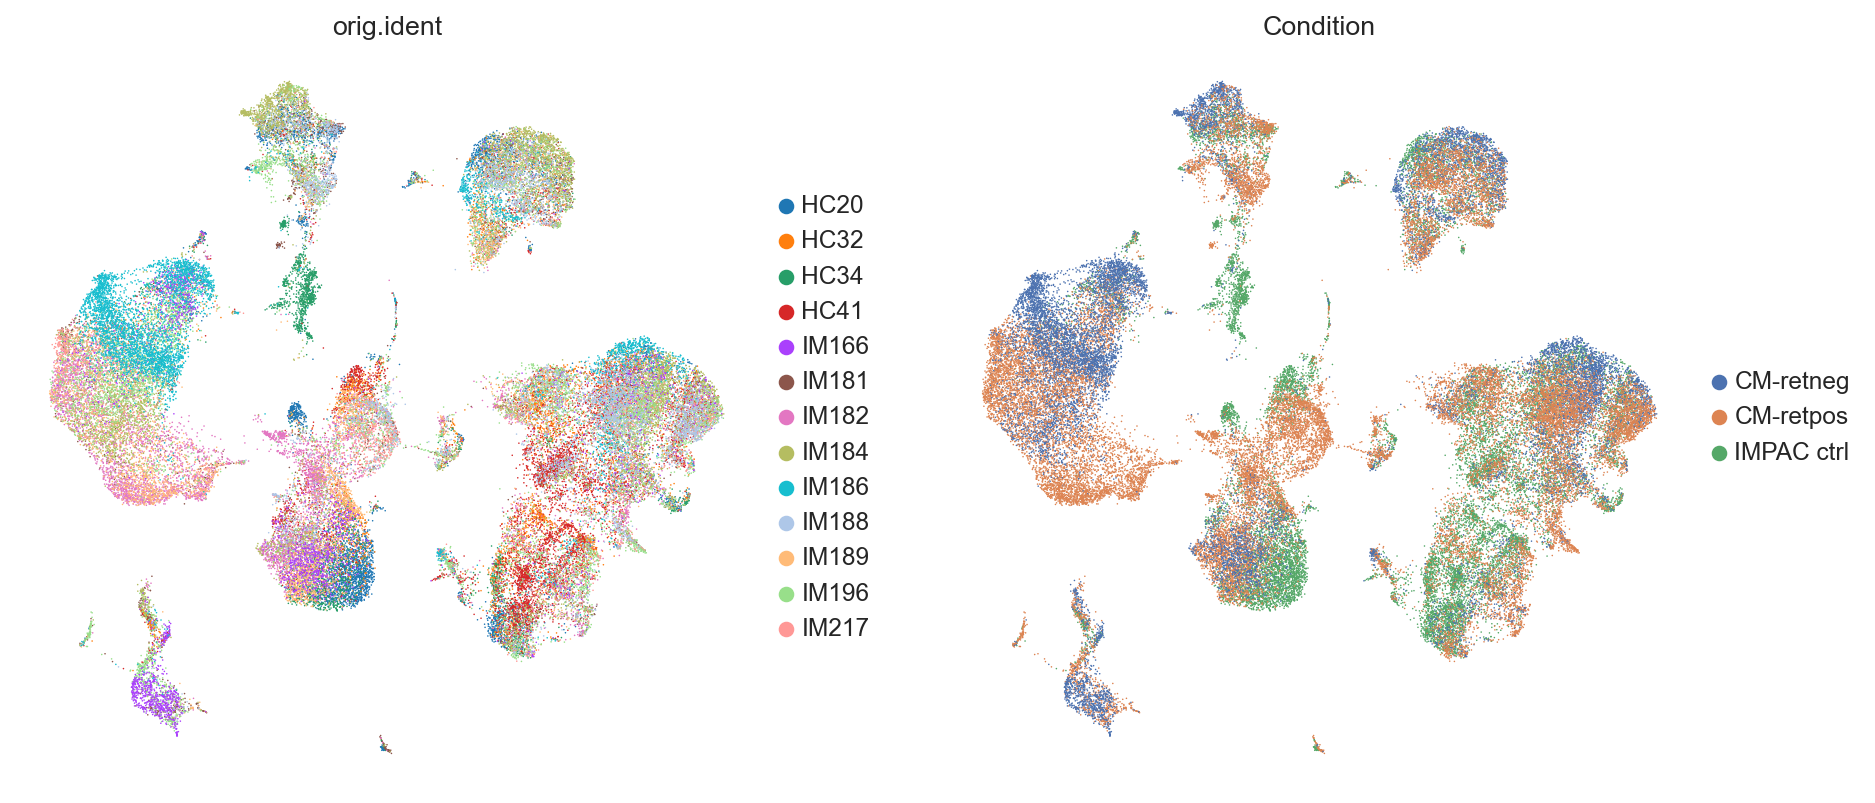

In [31]:
###visualize
sc.pl.umap(
    adata,
    color=["predicted.id"],
    frameon=False,
)
sc.pl.umap(
    adata,
    color=["orig.ident", "Condition"],
    ncols=2,
    frameon=False,
)

In [38]:
###cluster
# neighbors were already computed using scVI
SCVI_CLUSTERS_KEY = "leiden_scVI"
sc.tl.leiden(adata, key_added=SCVI_CLUSTERS_KEY, resolution=0.5)

/var/folders/9m/ht5rw9ws7tzg_spyt6tbk7zw0000gn/T/ipykernel_38594/2939402713.py:4: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, key_added=SCVI_CLUSTERS_KEY, resolution=0.5)


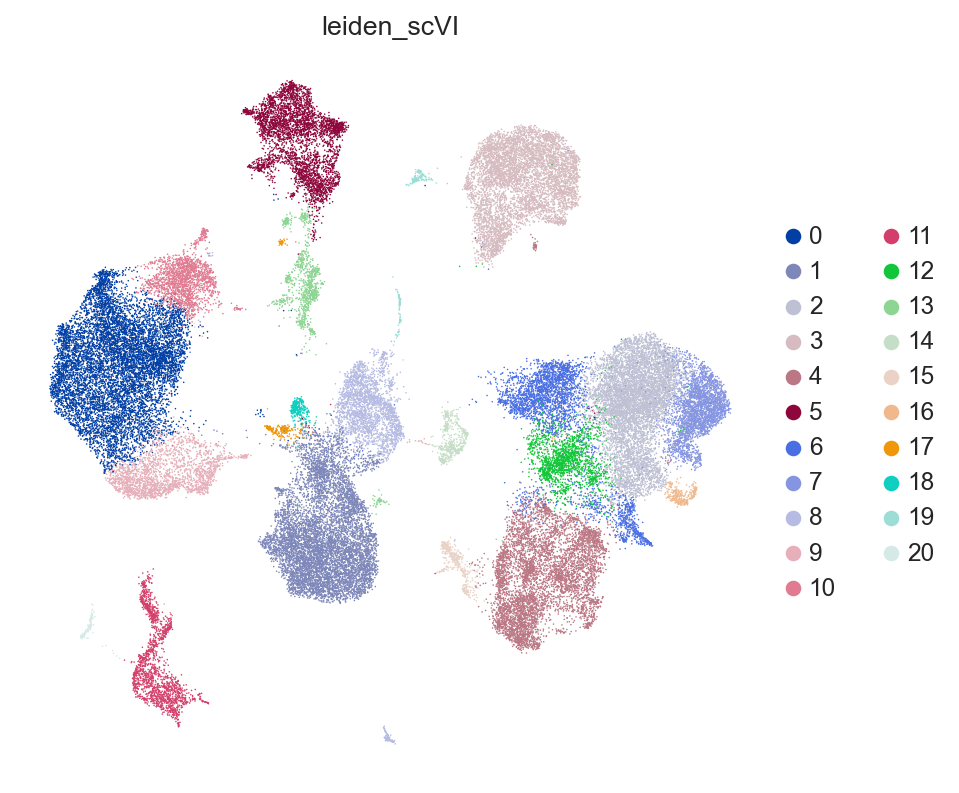

In [39]:
sc.pl.umap(
    adata,
    color=[SCVI_CLUSTERS_KEY],
    frameon=False,
)

In [40]:

# Save the integrated AnnData object
integrated_file = os.path.join(save_dir, "scvi_integrated_IMPAC.h5ad")

adata.write_h5ad(integrated_file)